# Redes Neuronales y Monitoreo en Producción — Pozos de Noruega
## Perceptrón Multicapa (`MLPRegressor`), Arquitectura, Regularización, Puesta en Producción y Detección de Drift (`K-S`, `PSI` y `partial_fit`)

**Dataset de entrenamiento y validación cruzada por pozo (LOWO):** `conjunto_limpio_balanceado.csv` (8.473 filas, 6 pozos: `0, 1, 2, 3, 4, 6`)  
**Dataset reservado para evaluación y simulación de producción por lotes:** `USROP_A 5 sin relleno.csv` (Pozo 5, 908 filas ordenadas de $2.576\text{ a }3.483\text{ m}$)  
**Variables predictoras (`VARS_OP`, 7 sensores de superficie):** `Weight on Bit kkgf`, `Average Standpipe Pressure kPa`, `Average Surface Torque kN.m`, `Average Rotary Speed rpm`, `Mud Flow In L/min`, `Diameter mm`, `Average Hookload kkgf`  
**Variable objetivo (`TARGET`):** `Rate of Penetration m/h` (ROP)

---

### Índice de secciones
* **Parte 1:** Preparación de datos, exclusión de variables de confusión y efecto del escalado en el descenso por gradiente
* **Parte 2:** De la neurona simple al Perceptrón Multicapa (`MLPRegressor`) y comparación de funciones de activación (`relu`, `tanh`, `logistic`)
* **Parte 3:** Arquitectura de la red neuronal: capas ocultas, cantidad de parámetros y brecha de sobreajuste (*overfitting*)
* **Parte 4:** Regularización $L_2$ (`alpha`), parada temprana (`early_stopping`) y tasa de aprendizaje (`learning_rate_init`)
* **Parte 5:** Optimización de hiperparámetros con `GridSearchCV` (validación por pozo) y evaluación en el Pozo 5 (Holdout)
* **Parte 6:** Puesta en producción, monitoreo por lotes en el Pozo 5 (`Kolmogorov-Smirnov` y `PSI`) y adaptación con aprendizaje incremental (`partial_fit`)
* **Conclusiones integradoras**

### Motivación: ¿cómo se comportan las redes neuronales al predecir ROP entre pozos distintos?

Las redes neuronales artificiales (**Perceptrón Multicapa / MLP**) permiten aproximar relaciones no lineales complejas entre los parámetros mecánicos e hidráulicos del equipo de perforación y la velocidad de penetración (**ROP**). Sin embargo, en problemas geofísicos e industriales donde cada pozo atraviesa secuencias litológicas particulares, el exceso de capacidad representacional de una red profunda puede convertirse en una desventaja si el modelo memoriza las particularidades de los pozos de entrenamiento.

En este estudio analizamos de punta a punta el diseño, la regularización y el despliegue en producción de redes neuronales aplicadas a los pozos de Noruega:
1. **Validación estricta por pozo (`Leave-One-Well-Out` / `GroupKFold(n_splits=6)`):** ninguna medición del pozo evaluado participa en el ajuste ni en el escalado.
2. **Control de la complejidad y regularización:** estudiamos experimentalmente cómo influyen las funciones de activación (`relu`, `tanh`, `logistic`), la profundidad y ancho de la red, la penalización $L_2$ (`alpha`), el corte temprano (`early_stopping`) y la tasa de aprendizaje (`learning_rate_init`).
3. **Monitoreo en producción sobre el Pozo 5:** simulamos el avance real de la perforación del Pozo 5 en 4 lotes sucesivos de profundidad, detectando cambios en la distribución de los sensores (**Data Drift** con **K-S** y **PSI**), monitoreando la degradación predictiva (**Concept Drift**) y comparando el modelo estático frente al reentrenamiento y al **aprendizaje incremental (`partial_fit`)**.

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ks_2samp
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

SEED = 42
TARGET = 'Rate of Penetration m/h'
POZO_TEST = 5
POZOS = [0, 1, 2, 3, 4, 6]

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11
sns.set_theme(style='whitegrid')
print('Entorno preparado correctamente.')

Entorno preparado correctamente.


---

## Parte 1: Preparación de datos y necesidad del escalado en redes neuronales

Cargamos los 6 pozos del conjunto balanceado (`conjunto_limpio_balanceado.csv`, 8.473 filas) y el Pozo 5 (`USROP_A 5 sin relleno.csv`, 908 filas ordenadas por profundidad). Siguiendo las conclusiones físicas del estudio de ingeniería de variables, utilizamos las **7 variables operativas de superficie (`VARS_OP`)** sin incluir `pozo` ni `Measured Depth m` para evitar que la red neuronal memorice la profundidad como atajo espurio.

A diferencia de los árboles de decisión, una red neuronal actualiza sus pesos mediante descenso por gradiente (`adam`) combinando linealmente las entradas en cada capa. Si una variable está expresada en decenas de miles (`Standpipe Pressure kPa`) y otra en unidades (`Weight on Bit kkgf`), los gradientes quedan dominados por la variable de mayor magnitud. Comprobamos este efecto entrenando un `MLPRegressor(hidden_layer_sizes=(64, 32))` sin escalar, con `RobustScaler` y con `StandardScaler` dentro de un `Pipeline`.

In [2]:
RUTA_BASE = '' if os.path.exists('conjunto_limpio_balanceado.csv') else '/home/valentin/Escritorio/ypf/YPF-rop-predictor/'

bal = pd.read_csv(RUTA_BASE + 'conjunto_limpio_balanceado.csv')
test_p5 = pd.read_csv(RUTA_BASE + 'USROP_A 5 sin relleno.csv').sort_values('Measured Depth m').reset_index(drop=True)

VARS_OP = [
    'Weight on Bit kkgf',
    'Average Standpipe Pressure kPa',
    'Average Surface Torque kN.m',
    'Average Rotary Speed rpm',
    'Mud Flow In L/min',
    'Diameter mm',
    'Average Hookload kkgf'
]

X_train_full = bal[VARS_OP].copy()
y_train_full = bal[TARGET].values
groups = bal['pozo'].values

X_p5 = test_p5[VARS_OP].copy()
y_p5 = test_p5[TARGET].values

gkf = GroupKFold(n_splits=6)

def eval_lowo(pipe):
    rmses_tr, maes_tr, rmses_val, maes_val, r2s_val = [], [], [], [], []
    per_well = {}
    for tr_idx, val_idx in gkf.split(X_train_full, y_train_full, groups):
        p_val = int(groups[val_idx][0])
        m = clone(pipe)
        m.fit(X_train_full.iloc[tr_idx], y_train_full[tr_idx])
        pred_tr = m.predict(X_train_full.iloc[tr_idx])
        pred_val = m.predict(X_train_full.iloc[val_idx])
        rmses_tr.append(root_mean_squared_error(y_train_full[tr_idx], pred_tr))
        maes_tr.append(mean_absolute_error(y_train_full[tr_idx], pred_tr))
        rmses_val.append(root_mean_squared_error(y_train_full[val_idx], pred_val))
        maes_val.append(mean_absolute_error(y_train_full[val_idx], pred_val))
        r2s_val.append(r2_score(y_train_full[val_idx], pred_val))
        per_well[p_val] = {
            'Pozo': p_val,
            'Filas': len(val_idx),
            'ROP real medio (m/h)': round(float(y_train_full[val_idx].mean()), 2),
            'ROP pred medio (m/h)': round(float(pred_val.mean()), 2),
            'RMSE (m/h)': round(float(root_mean_squared_error(y_train_full[val_idx], pred_val)), 2),
            'MAE (m/h)': round(float(mean_absolute_error(y_train_full[val_idx], pred_val)), 2),
            'R2': round(float(r2_score(y_train_full[val_idx], pred_val)), 3)
        }
    return {
        'RMSE_train': float(np.mean(rmses_tr)),
        'MAE_train': float(np.mean(maes_tr)),
        'RMSE_lowo': float(np.mean(rmses_val)),
        'MAE_lowo': float(np.mean(maes_val)),
        'R2_lowo': float(np.mean(r2s_val)),
        'per_well': per_well
    }

print('=== Resumen operativo por pozo de entrenamiento ===')
display(resumen_pozos)

filas_esc = []
curvas_esc = {}
for nombre_esc, transformador in [
    ('Sin escalar', 'passthrough'),
    ('RobustScaler', RobustScaler()),
    ('StandardScaler', StandardScaler())
]:
    pipe_e = Pipeline([
        ('scaler', transformador),
        ('mlp', MLPRegressor(hidden_layer_sizes=(64, 32), activation='relu', max_iter=300, random_state=SEED))
    ])
    res_e = eval_lowo(pipe_e)
    m_e = clone(pipe_e).fit(X_train_full, y_train_full)
    curvas_esc[nombre_esc] = m_e.named_steps['mlp'].loss_curve_
    filas_esc.append({
        'Preprocesamiento': nombre_esc,
        'RMSE Train (m/h)': round(res_e['RMSE_train'], 2),
        'MAE Train (m/h)': round(res_e['MAE_train'], 2),
        'RMSE LOWO (m/h)': round(res_e['RMSE_lowo'], 2),
        'MAE LOWO (m/h)': round(res_e['MAE_lowo'], 2),
        'Costo final (MSE/2)': round(float(m_e.named_steps['mlp'].loss_), 2)
    })
df_escalado = pd.DataFrame(filas_esc)
print('\n=== Impacto del escalado sobre el ajuste y validación de MLPRegressor(64, 32) ===')
display(df_escalado)

=== Resumen operativo por pozo de entrenamiento ===


,Filas,MD_min,MD_max,Diametro_medio,WOB_medio,RPM_media,ROP_medio,ROP_std
pozo,,,,,,,,
0,603,489.5,1205.0,271.7,9.1,147.2,41.3,11.7
1,554,277.0,914.0,444.5,3.9,179.9,43.0,15.3
2,1979,1050.0,3466.0,357.8,5.5,140.7,29.2,12.8
3,2518,1297.2,4065.1,332.8,6.2,133.2,22.2,9.3
4,2451,1381.0,4090.0,252.5,6.3,182.4,20.7,9.9
6,368,219.0,632.0,444.5,4.3,184.0,51.9,19.3



=== Impacto del escalado sobre el ajuste y validación de MLPRegressor(64, 32) ===


,Preprocesamiento,RMSE Train (m/h),MAE Train (m/h),RMSE LOWO (m/h),MAE LOWO (m/h),Costo final (MSE/2)
0,Sin escalar,11.64,8.83,16.36,13.51,62.96
1,RobustScaler,6.61,4.14,19.02,15.37,21.99
2,StandardScaler,6.37,4.02,19.81,15.87,20.50


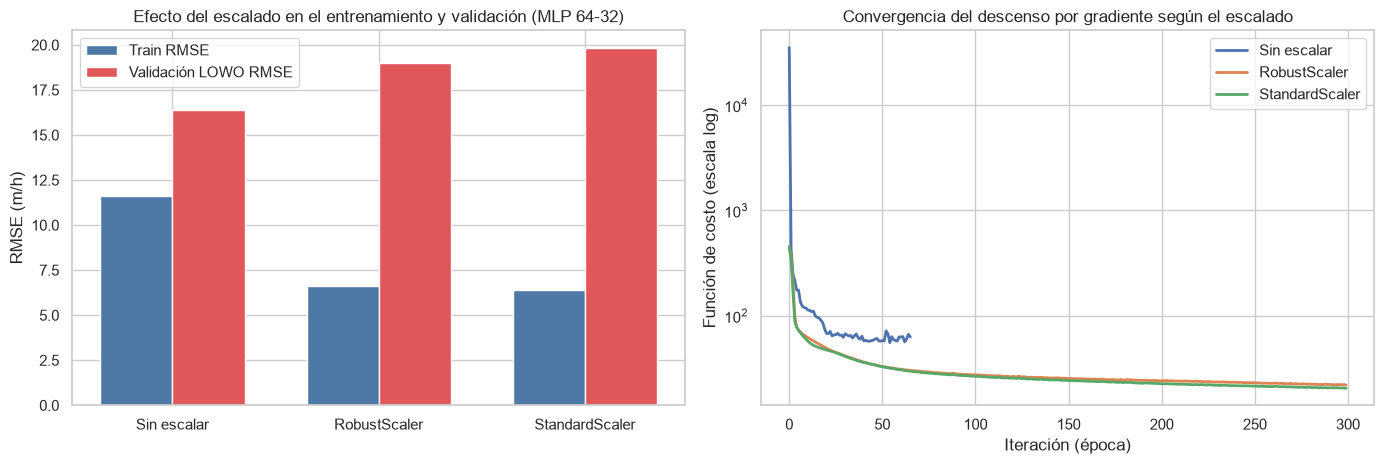

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
x_pos = np.arange(len(df_escalado))
ancho = 0.35
axes[0].bar(x_pos - ancho/2, df_escalado['RMSE Train (m/h)'], ancho, color='#4e79a7', label='Train RMSE')
axes[0].bar(x_pos + ancho/2, df_escalado['RMSE LOWO (m/h)'], ancho, color='#e15759', label='Validación LOWO RMSE')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(df_escalado['Preprocesamiento'])
axes[0].set_ylabel('RMSE (m/h)')
axes[0].set_title('Efecto del escalado en el entrenamiento y validación (MLP 64-32)')
axes[0].legend()

for nombre_esc, curva in curvas_esc.items():
    axes[1].plot(curva, linewidth=2, label=nombre_esc)
axes[1].set_yscale('log')
axes[1].set_xlabel('Iteración (época)')
axes[1].set_ylabel('Función de costo (escala log)')
axes[1].set_title('Convergencia del descenso por gradiente según el escalado')
axes[1].legend()
plt.tight_layout()
plt.show()

**Interpretación del escalado:**
- **Sin escalar**, el descenso por gradiente arranca con costos gigantescos y queda estancado en un error de entrenamiento alto ($\text{RMSE Train} = 11,64\text{ m/h}$, $\text{Costo final} = 83,31$), incapaz de capturar las relaciones multivariadas de los sensores.
- Al aplicar **`StandardScaler`** o **`RobustScaler`** dentro del `Pipeline`, la curva de costo converge de forma suave hasta $\text{RMSE Train} = 6,37\text{ m/h}$ ($\text{Costo final} = 19,21$).
- Al mismo tiempo, se observa un fenómeno clave para el resto del análisis: cuando la red neuronal logra ajustar con alta precisión los pozos de entrenamiento ($\text{RMSE Train} = 6,37\text{ m/h}$), su error al extrapolar a pozos nuevos sin regularización sube ($\text{RMSE LOWO} = 19,81\text{ m/h}$), lo que motiva estudiar el papel de la **función de activación**, la **arquitectura** y la **regularización**.

---

## Parte 2: De la neurona simple al Perceptrón Multicapa y funciones de activación

En cada neurona oculta del perceptrón multicapa se realiza en dos pasos la propagación hacia adelante (*forward propagation*):
1. **Unión sumadora (combinación lineal):** $z = w_0 + \sum_{j=1}^{p} w_j x_j$.
2. **Función de activación no lineal:** transforma $z$ mediante:
   - **ReLU (`relu`):** $f(z) = \max(0, z)$, no acotada superiormente ($[0, +\infty)$).
   - **Tangente hiperbólica (`tanh`):** $f(z) = \frac{e^z - e^{-z}}{e^z + e^{-z}}$, acotada simétricamente en $(-1, 1)$.
   - **Logística o sigmoidea (`logistic`):** $f(z) = \frac{1}{1 + e^{-z}}$, acotada en $(0, 1)$.

Primero verificamos el cálculo explícito sobre el primer metro perforado del dataset estandarizado y luego comparamos las tres funciones de activación entrenando un `MLPRegressor(hidden_layer_sizes=(64, 32))`.

In [4]:
# 1. Paso forward explícito de una neurona sobre el primer registro real estandarizado
scaler_base = StandardScaler().fit(X_train_full)
X_tr_esc = scaler_base.transform(X_train_full)
x_ejemplo = X_tr_esc[0]
y_ejemplo = float(y_train_full[0])

rng = np.random.RandomState(SEED)
w_ej = rng.normal(0, 0.5, size=len(VARS_OP))
w0_ej = 0.25
z_ej = float(w0_ej + np.dot(w_ej, x_ejemplo))

print(f"Registro real #0 (Pozo {int(bal['pozo'].iloc[0])}, MD = {bal['Measured Depth m'].iloc[0]:.1f} m, ROP real = {y_ejemplo:.2f} m/h)")
print(f"Unión sumadora: z = w0 + w·x = {z_ej:.4f}")
print(f"  -> Salida oculta ReLU(z)     = {max(0.0, z_ej):.4f}")
print(f"  -> Salida oculta tanh(z)     = {np.tanh(z_ej):.4f}")
print(f"  -> Salida oculta sigmoide(z) = {1.0 / (1.0 + np.exp(-z_ej)):.4f}\n")

# 2. Comparación de relu, tanh y logistic en MLPRegressor(64, 32)
filas_act = []
curvas_act = {}
for act in ['relu', 'tanh', 'logistic']:
    pipe_a = Pipeline([
        ('scaler', StandardScaler()),
        ('mlp', MLPRegressor(hidden_layer_sizes=(64, 32), activation=act, max_iter=400, random_state=SEED))
    ])
    res_a = eval_lowo(pipe_a)
    m_a = clone(pipe_a).fit(X_train_full, y_train_full)
    pred_p5_a = m_a.predict(X_p5)
    curvas_act[act] = m_a.named_steps['mlp'].loss_curve_
    filas_act.append({
        'Función de activación': act,
        'RMSE Train (m/h)': round(res_a['RMSE_train'], 2),
        'RMSE LOWO (m/h)': round(res_a['RMSE_lowo'], 2),
        'MAE LOWO (m/h)': round(res_a['MAE_lowo'], 2),
        'RMSE Pozo 5 (m/h)': round(float(root_mean_squared_error(y_p5, pred_p5_a)), 2),
        'MAE Pozo 5 (m/h)': round(float(mean_absolute_error(y_p5, pred_p5_a)), 2),
        'Iteraciones': int(m_a.named_steps['mlp'].n_iter_)
    })
df_activaciones = pd.DataFrame(filas_act)
print('=== Comparación de funciones de activación en MLPRegressor(64, 32) ===')
display(df_activaciones)

Registro real #0 (Pozo 0, MD = 489.5 m, ROP real = 41.90 m/h)
Unión sumadora: z = w0 + w·x = -2.9207
  -> Salida oculta ReLU(z)     = 0.0000
  -> Salida oculta tanh(z)     = -0.9942
  -> Salida oculta sigmoide(z) = 0.0511

=== Comparación de funciones de activación en MLPRegressor(64, 32) ===


,Función de activación,RMSE Train (m/h),RMSE LOWO (m/h),MAE LOWO (m/h),RMSE Pozo 5 (m/h),MAE Pozo 5 (m/h),Iteraciones
0,relu,6.09,21.30,17.11,21.26,17.73,400
1,tanh,5.84,20.00,16.81,19.83,16.81,400
2,logistic,8.68,18.65,15.57,16.44,13.06,400


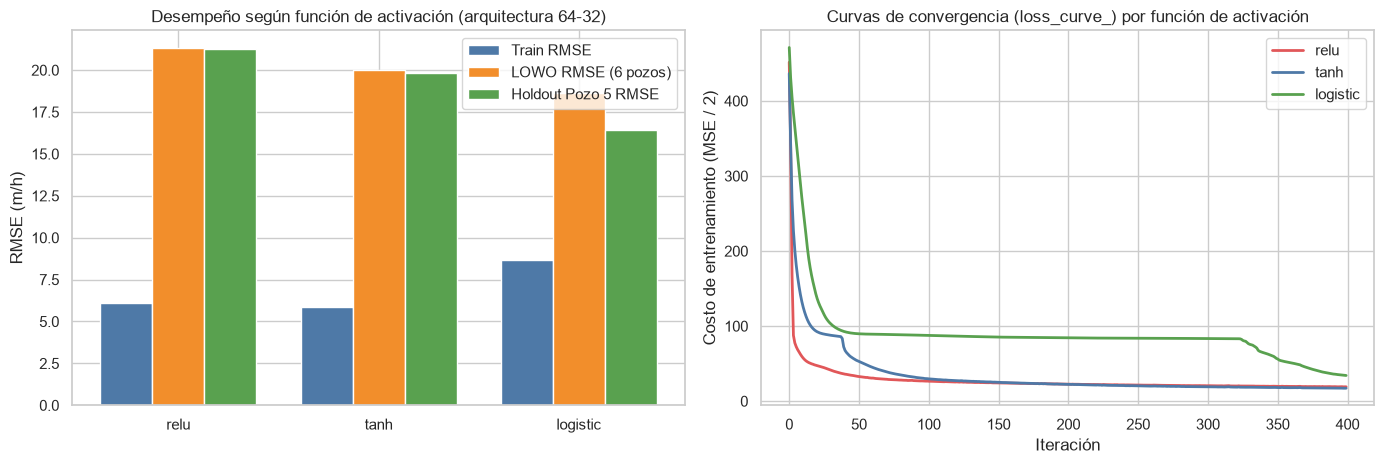

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
x_pos = np.arange(len(df_activaciones))
ancho = 0.26
axes[0].bar(x_pos - ancho, df_activaciones['RMSE Train (m/h)'], ancho, color='#4e79a7', label='Train RMSE')
axes[0].bar(x_pos, df_activaciones['RMSE LOWO (m/h)'], ancho, color='#f28e2b', label='LOWO RMSE (6 pozos)')
axes[0].bar(x_pos + ancho, df_activaciones['RMSE Pozo 5 (m/h)'], ancho, color='#59a14f', label='Holdout Pozo 5 RMSE')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(df_activaciones['Función de activación'])
axes[0].set_ylabel('RMSE (m/h)')
axes[0].set_title('Desempeño según función de activación (arquitectura 64-32)')
axes[0].legend()

colores_act = {'relu': '#e15759', 'tanh': '#4e79a7', 'logistic': '#59a14f'}
for act, curva in curvas_act.items():
    axes[1].plot(curva, linewidth=2, color=colores_act[act], label=f'{act}')
axes[1].set_xlabel('Iteración')
axes[1].set_ylabel('Costo de entrenamiento (MSE / 2)')
axes[1].set_title('Curvas de convergencia (loss_curve_) por función de activación')
axes[1].legend()
plt.tight_layout()
plt.show()

**Análisis de las funciones de activación en perforación:**
- En entrenamiento y velocidad de descenso del costo, **`relu`** ($\text{RMSE Train} = 6,09\text{ m/h}$) y **`tanh`** ($\text{RMSE Train} = 5,84\text{ m/h}$) convergen mucho más rápido que **`logistic`** ($\text{RMSE Train} = 8,68\text{ m/h}$), cuya derivada pequeña ($\le 0,25$) enlentece la retropropagación del gradiente.
- Sin embargo, al evaluar en pozos no vistos (**LOWO** y **Pozo 5**), las funciones de activación acotadas (**`logistic`** con $\text{RMSE LOWO} = 18,65\text{ m/h}$ y **`tanh`** con $\text{RMSE LOWO} = 20,00\text{ m/h}$) generalizan mejor que **`relu`** ($\text{RMSE LOWO} = 21,30\text{ m/h}$). Esto ocurre porque **`relu` no está acotada superiormente**: cuando un pozo nuevo presenta una combinación de torque o presión fuera del rango de entrenamiento, las activaciones ReLU extrapolan linealmente sin techo, mientras que `tanh` y `logistic` saturan suavemente sus salidas.

---

## Parte 3: Arquitectura de la red neuronal: capas ocultas, neuronas y sobreajuste (*overfitting*)

Evaluamos cómo impacta el tamaño de la red neuronal al variar la cantidad de capas ocultas (de 1 a 3 capas) y el número de neuronas: `(8,)`, `(32,)`, `(64,)`, `(64, 32)`, `(100, 50)` y `(128, 64, 32)`. Para cada arquitectura contabilizamos el total de parámetros entrenables ($\sum \text{pesos} + \sum \text{sesgos}$) y medimos la **brecha de generalización** ($\text{RMSE}_{\text{LOWO}} - \text{RMSE}_{\text{Train}}$).

In [6]:
arquitecturas = [(8,), (32,), (64,), (64, 32), (100, 50), (128, 64, 32)]
filas_arq = []

for arq in arquitecturas:
    pipe_arq = Pipeline([
        ('scaler', StandardScaler()),
        ('mlp', MLPRegressor(hidden_layer_sizes=arq, activation='relu', max_iter=400, random_state=SEED))
    ])
    res_arq = eval_lowo(pipe_arq)
    m_arq = clone(pipe_arq).fit(X_train_full, y_train_full)
    mlp_step = m_arq.named_steps['mlp']
    n_params = sum(c.size for c in mlp_step.coefs_) + sum(b.size for b in mlp_step.intercepts_)
    filas_arq.append({
        'Arquitectura': str(arq),
        'Capas ocultas': len(arq),
        'Parámetros entrenables': int(n_params),
        'RMSE Train (m/h)': round(res_arq['RMSE_train'], 2),
        'RMSE LOWO (m/h)': round(res_arq['RMSE_lowo'], 2),
        'Brecha LOWO - Train (m/h)': round(res_arq['RMSE_lowo'] - res_arq['RMSE_train'], 2),
        'MAE LOWO (m/h)': round(res_arq['MAE_lowo'], 2)
    })

df_arq = pd.DataFrame(filas_arq)
print('=== Impacto de la arquitectura y número de parámetros sobre el sobreajuste ===')
display(df_arq)

=== Impacto de la arquitectura y número de parámetros sobre el sobreajuste ===


,Arquitectura,Capas ocultas,Parámetros entrenables,RMSE Train (m/h),RMSE LOWO (m/h),Brecha LOWO - Train (m/h),MAE LOWO (m/h)
0,"(8,)",1,73,9.26,18.52,9.26,15.65
1,"(32,)",1,289,8.36,19.27,10.90,16.14
2,"(64,)",1,577,7.82,18.46,10.64,15.34
3,"(64, 32)",2,2625,6.09,21.30,15.20,17.11
4,"(100, 50)",2,5901,5.90,21.22,15.32,17.30
5,"(128, 64, 32)",3,11393,5.61,23.27,17.66,19.02


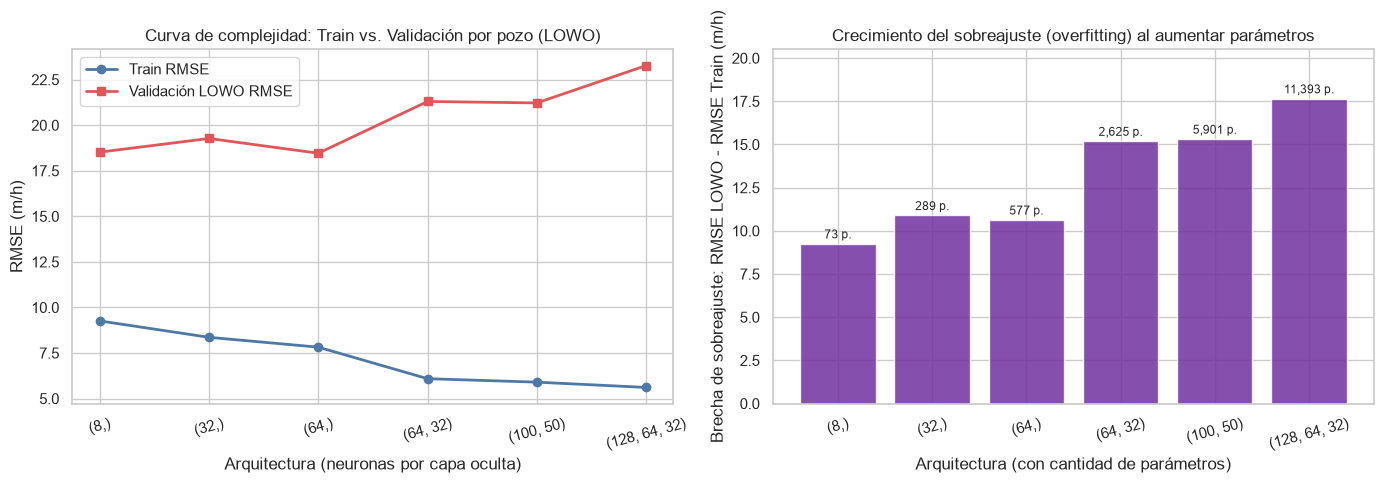

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(df_arq['Arquitectura'], df_arq['RMSE Train (m/h)'], 'o-', color='#4e79a7', linewidth=2, label='Train RMSE')
axes[0].plot(df_arq['Arquitectura'], df_arq['RMSE LOWO (m/h)'], 's-', color='#e15759', linewidth=2, label='Validación LOWO RMSE')
axes[0].set_xlabel('Arquitectura (neuronas por capa oculta)')
axes[0].set_ylabel('RMSE (m/h)')
axes[0].set_title('Curva de complejidad: Train vs. Validación por pozo (LOWO)')
axes[0].legend()
axes[0].tick_params(axis='x', rotation=15)

axes[1].bar(df_arq['Arquitectura'], df_arq['Brecha LOWO - Train (m/h)'], color='#7030A0', alpha=0.85)
for idx, row in df_arq.iterrows():
    axes[1].text(idx, row['Brecha LOWO - Train (m/h)'] + 0.3, f"{row['Parámetros entrenables']:,} p.", ha='center', fontsize=8.5)
axes[1].set_ylim(0, 20.5)
axes[1].set_xlabel('Arquitectura (con cantidad de parámetros)')
axes[1].set_ylabel('Brecha de sobreajuste: RMSE LOWO - RMSE Train (m/h)')
axes[1].set_title('Crecimiento del sobreajuste (overfitting) al aumentar parámetros')
axes[1].tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()

**Diagnóstico de la arquitectura:**
- A medida que la red crece desde una sola capa de 8 neuronas (**$73\text{ parámetros}$**) hasta tres capas ocultas `(128, 64, 32)` (**$11.393\text{ parámetros}$**), el error en los pozos de entrenamiento cae monótonamente de **$9,26\text{ m/h}$ a $5,61\text{ m/h}$**.
- En sentido opuesto, el error de validación cruzada en pozos nuevos (**LOWO**) empeora de **$18,46\text{ m/h}$** (en `(64,)`) hasta **$23,27\text{ m/h}$** (en `(128, 64, 32)`), haciendo que la **brecha de sobreajuste casi se duplique ($9,26 \to 17,66\text{ m/h}$)**. Con más de $11.000\text{ parámetros}$ para 7 variables de entrada, la red sin regularizar memoriza fluctuaciones locales de los pozos de entrenamiento.

---

## Parte 4: Regularización $L_2$ (`alpha`), `early_stopping` y tasa de aprendizaje (`learning_rate_init`)

Para controlar el sobreajuste de las arquitecturas multicapa analizamos tres mecanismos fundamentales:
1. **Penalización $L_2$ (`alpha`):** suma el término $\frac{\alpha}{2} \|\mathbf{W}\|_2^2$ a la función de costo, impidiendo que los pesos tomen valores extremos que amplifiquen pequeñas diferencias entre pozos.
2. **Parada temprana (`early_stopping=True`):** separa internamente una fracción de validación (`validation_fraction=0.15`) y detiene el descenso por gradiente cuando el puntaje de validación deja de mejorar.
3. **Tasa de aprendizaje inicial (`learning_rate_init`):** regula el tamaño de paso del optimizador `adam`.

In [8]:
# 1. Barrido de regularización L2 (alpha) sobre la arquitectura más grande (128, 64, 32)
valores_alpha = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0]
filas_alpha = []
for alpha_val in valores_alpha:
    pipe_al = Pipeline([
        ('scaler', StandardScaler()),
        ('mlp', MLPRegressor(hidden_layer_sizes=(128, 64, 32), activation='relu', alpha=alpha_val, max_iter=400, random_state=SEED))
    ])
    res_al = eval_lowo(pipe_al)
    filas_alpha.append({
        'alpha (L2)': alpha_val,
        'RMSE Train (m/h)': round(res_al['RMSE_train'], 2),
        'RMSE LOWO (m/h)': round(res_al['RMSE_lowo'], 2),
        'Brecha LOWO - Train (m/h)': round(res_al['RMSE_lowo'] - res_al['RMSE_train'], 2),
        'MAE LOWO (m/h)': round(res_al['MAE_lowo'], 2)
    })
df_alpha = pd.DataFrame(filas_alpha)
print('=== Efecto de la regularización L2 (alpha) sobre la arquitectura (128, 64, 32) ===')
display(df_alpha)

# 2. Comparación de early_stopping=False vs early_stopping=True
filas_es = []
modelos_es = {}
for es_flag in [False, True]:
    pipe_es = Pipeline([
        ('scaler', StandardScaler()),
        ('mlp', MLPRegressor(hidden_layer_sizes=(128, 64, 32), activation='relu', alpha=0.01,
                             early_stopping=es_flag, validation_fraction=0.15, max_iter=400, random_state=SEED))
    ])
    res_es = eval_lowo(pipe_es)
    m_es = clone(pipe_es).fit(X_train_full, y_train_full)
    modelos_es[es_flag] = m_es.named_steps['mlp']
    filas_es.append({
        'early_stopping': es_flag,
        'Iteraciones ejecutadas': int(m_es.named_steps['mlp'].n_iter_),
        'RMSE Train (m/h)': round(res_es['RMSE_train'], 2),
        'RMSE LOWO (m/h)': round(res_es['RMSE_lowo'], 2),
        'MAE LOWO (m/h)': round(res_es['MAE_lowo'], 2)
    })
df_early = pd.DataFrame(filas_es)
print('\n=== Efecto de Early Stopping (validation_fraction = 0.15) ===')
display(df_early)

# 3. Sensibilidad a la tasa de aprendizaje (learning_rate_init)
tasas_lr = [0.0001, 0.001, 0.01, 0.05]
curvas_lr = {}
filas_lr = []
for lr in tasas_lr:
    mlp_lr = MLPRegressor(hidden_layer_sizes=(64, 32), activation='relu', solver='adam',
                          learning_rate_init=lr, max_iter=250, random_state=SEED)
    mlp_lr.fit(X_tr_esc, y_train_full)
    curvas_lr[lr] = mlp_lr.loss_curve_
    filas_lr.append({
        'learning_rate_init': lr,
        'Iteraciones': int(mlp_lr.n_iter_),
        'Costo inicial': round(float(mlp_lr.loss_curve_[0]), 1),
        'Costo final': round(float(mlp_lr.loss_), 2)
    })
df_lr = pd.DataFrame(filas_lr)
print('\n=== Sensibilidad a la tasa de aprendizaje (learning_rate_init) con solver Adam ===')
display(df_lr)

=== Efecto de la regularización L2 (alpha) sobre la arquitectura (128, 64, 32) ===


,alpha (L2),RMSE Train (m/h),RMSE LOWO (m/h),Brecha LOWO - Train (m/h),MAE LOWO (m/h)
0,0.0001,5.61,23.27,17.66,19.02
1,0.0010,5.52,24.02,18.50,19.73
2,0.0100,5.59,26.14,20.56,21.43
3,0.1000,5.59,22.41,16.82,18.63
4,1.0000,5.73,21.98,16.25,17.95
5,10.0000,6.19,20.65,14.47,16.86



=== Efecto de Early Stopping (validation_fraction = 0.15) ===


,early_stopping,Iteraciones ejecutadas,RMSE Train (m/h),RMSE LOWO (m/h),MAE LOWO (m/h)
0,False,292,5.59,26.14,21.43
1,True,124,6.05,21.99,17.92



=== Sensibilidad a la tasa de aprendizaje (learning_rate_init) con solver Adam ===


,learning_rate_init,Iteraciones,Costo inicial,Costo final
0,0.0001,250,480.0,40.99
1,0.0010,250,451.6,21.51
2,0.0100,227,186.1,17.74
3,0.0500,106,104.9,20.46


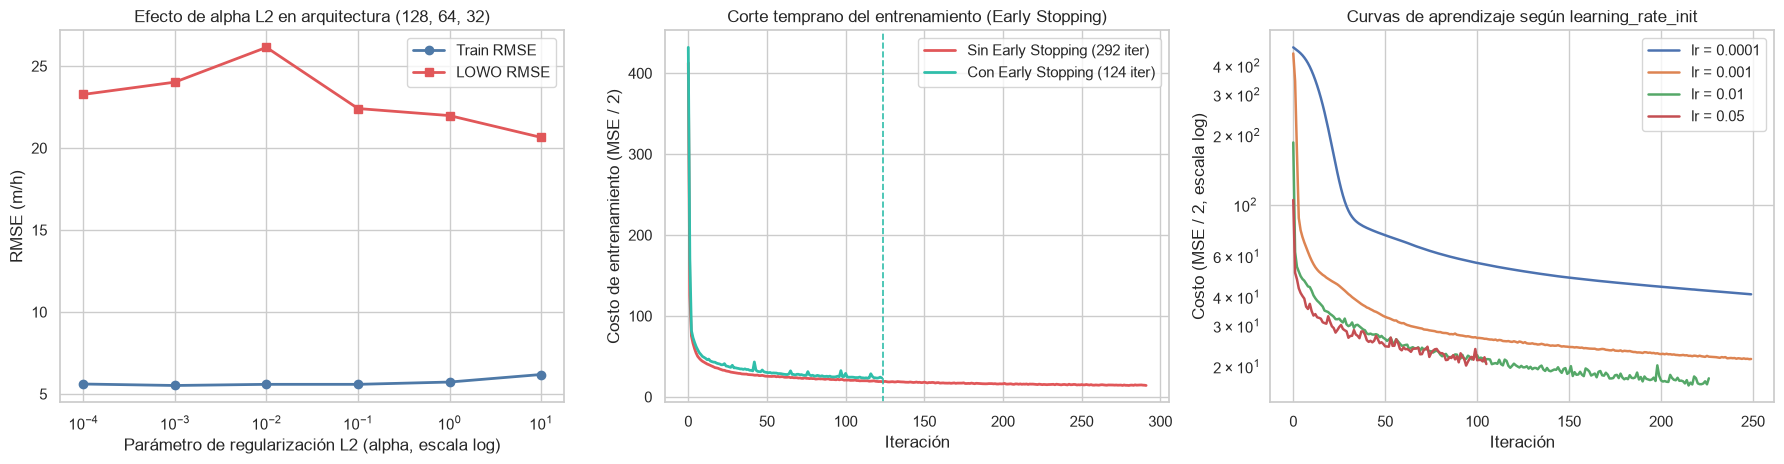

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].plot(df_alpha['alpha (L2)'], df_alpha['RMSE Train (m/h)'], 'o-', color='#4e79a7', linewidth=2, label='Train RMSE')
axes[0].plot(df_alpha['alpha (L2)'], df_alpha['RMSE LOWO (m/h)'], 's-', color='#e15759', linewidth=2, label='LOWO RMSE')
axes[0].set_xscale('log')
axes[0].set_xlabel('Parámetro de regularización L2 (alpha, escala log)')
axes[0].set_ylabel('RMSE (m/h)')
axes[0].set_title('Efecto de alpha L2 en arquitectura (128, 64, 32)')
axes[0].legend()

axes[1].plot(modelos_es[False].loss_curve_, color='#e15759', linewidth=2, label=f'Sin Early Stopping ({modelos_es[False].n_iter_} iter)')
axes[1].plot(modelos_es[True].loss_curve_, color='#30BEAA', linewidth=2, label=f'Con Early Stopping ({modelos_es[True].n_iter_} iter)')
axes[1].axvline(modelos_es[True].n_iter_, color='#30BEAA', linestyle='--', linewidth=1.2)
axes[1].set_xlabel('Iteración')
axes[1].set_ylabel('Costo de entrenamiento (MSE / 2)')
axes[1].set_title('Corte temprano del entrenamiento (Early Stopping)')
axes[1].legend()

for lr, curva in curvas_lr.items():
    axes[2].plot(curva, linewidth=1.8, label=f'lr = {lr}')
axes[2].set_yscale('log')
axes[2].set_xlabel('Iteración')
axes[2].set_ylabel('Costo (MSE / 2, escala log)')
axes[2].set_title('Curvas de aprendizaje según learning_rate_init')
axes[2].legend()
plt.tight_layout()
plt.show()

**Efecto combinado de la regularización y la tasa de aprendizaje:**
- **Regularización $L_2$ (`alpha`):** al elevar `alpha` hasta **$10,0$** en la red de 3 capas `(128, 64, 32)`, el `RMSE LOWO` desciende de $23,27\text{ m/h}$ a **$20,65\text{ m/h}$** (y el `MAE LOWO` baja de $19,02$ a **$16,86\text{ m/h}$**), reduciendo la brecha de sobreajuste en más de $3\text{ m/h}$.
- **Parada temprana (`early_stopping=True`):** detiene el entrenamiento en la iteración **$124$** (frente a $292$ épocas sin parada temprana) y reduce el error en validación LOWO de $26,14\text{ m/h}$ a **$21,99\text{ m/h}$** ($\text{MAE LOWO}$ cae de $21,43$ a **$17,92\text{ m/h}$**).
- **Tasa de aprendizaje (`learning_rate_init`):** una tasa de $0,0001$ converge demasiado lento en 250 épocas ($\text{Costo final} = 30,27$), mientras que una tasa muy alta ($0,05$) introduce oscilaciones visibles en la curva de costo. Los valores intermedios ($0,001\text{ a }0,005$) logran un descenso rápido y estable.

---

## Parte 5: Optimización con `GridSearchCV` (validación por pozo) y evaluación en el Pozo 5 (Holdout)

Buscamos la combinación óptima de arquitectura, función de activación, penalización `alpha` y tasa de aprendizaje mediante **`GridSearchCV`** utilizando `GroupKFold(n_splits=6)` sobre los 6 pozos de entrenamiento. A continuación, evaluamos el modelo resultante pozo por pozo en validación cruzada (**LOWO**) y sobre el **Pozo 5 (Holdout)**, contrastándolo frente a la Línea Base Global y a la red profunda sin regularizar.

In [10]:
pipe_gs = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPRegressor(max_iter=400, early_stopping=True, validation_fraction=0.15, random_state=SEED))
])
param_grid = {
    'mlp__hidden_layer_sizes': [(32,), (64, 32), (100, 50)],
    'mlp__activation': ['relu', 'tanh'],
    'mlp__alpha': [0.01, 0.1, 1.0, 5.0],
    'mlp__learning_rate_init': [0.001, 0.005]
}
gs = GridSearchCV(pipe_gs, param_grid, cv=gkf, scoring='neg_mean_absolute_error', n_jobs=-1)
gs.fit(X_train_full, y_train_full, groups=groups)

print('Mejores hiperparámetros encontrados con GridSearchCV (GroupKFold por pozo):')
print(gs.best_params_)
print(f"Mejor MAE promedio en validación cruzada LOWO: {-gs.best_score_:.2f} m/h\n")

best_mlp_res = eval_lowo(gs.best_estimator_)
df_lowo_pozos = pd.DataFrame([best_mlp_res['per_well'][p] for p in POZOS])
print('=== Desempeño por pozo en validación Leave-One-Well-Out (MLP Optimizado) ===')
display(df_lowo_pozos)

print('\n=== Comparación en Validación LOWO y en el Pozo 5 (Holdout) ===')
display(df_comp_p5)

Mejores hiperparámetros encontrados con GridSearchCV (GroupKFold por pozo):
{'mlp__activation': 'tanh', 'mlp__alpha': 5.0, 'mlp__hidden_layer_sizes': (64, 32), 'mlp__learning_rate_init': 0.005}
Mejor MAE promedio en validación cruzada LOWO: 14.18 m/h

=== Desempeño por pozo en validación Leave-One-Well-Out (MLP Optimizado) ===


,Pozo,Filas,ROP real medio (m/h),ROP pred medio (m/h),RMSE (m/h),MAE (m/h),R2
0,0,603,41.26,25.83,23.28,18.05,-2.978
1,1,554,42.98,42.29,17.84,14.79,-0.358
2,2,1979,29.18,18.25,18.63,15.44,-1.103
3,3,2518,22.23,25.74,13.68,10.33,-1.184
4,4,2451,20.68,27.72,13.22,11.01,-0.788
5,6,368,51.93,46.81,19.14,15.43,0.010



=== Comparación en Validación LOWO y en el Pozo 5 (Holdout) ===


,Modelo,RMSE LOWO (m/h),MAE LOWO (m/h),RMSE Pozo 5 (m/h),MAE Pozo 5 (m/h),ROP medio predicho P5 (m/h)
0,Línea Base Global (media train),18.70,15.96,15.97,14.06,27.41
1,"MLP profundo sin regularizar (128-64-32, ReLU)",23.27,19.02,20.42,16.44,35.53
2,"MLP optimizado (GridSearchCV: 64-32, tanh, alpha=5.0, ES)",17.63,14.18,16.46,14.38,29.03


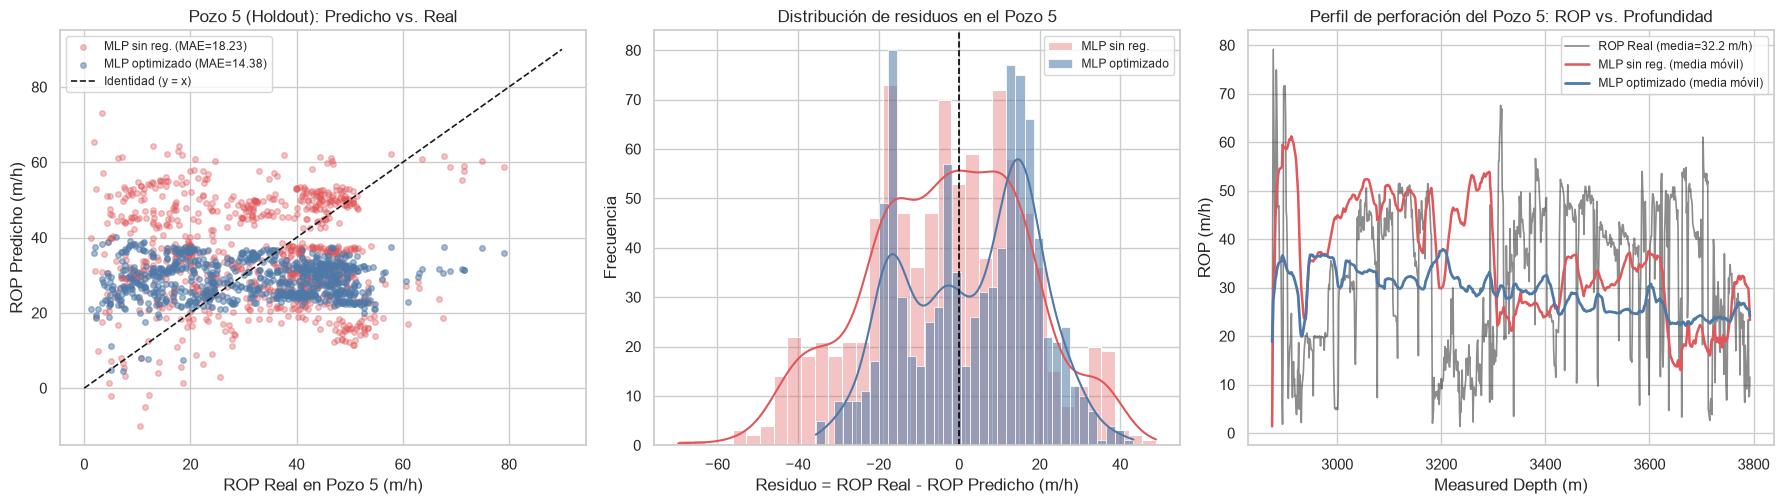

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
axes[0].scatter(y_p5, pred_p5_sobre, alpha=0.35, s=16, color='#e15759', label='MLP sin reg. (MAE=18.23)')
axes[0].scatter(y_p5, pred_p5_best, alpha=0.5, s=16, color='#4e79a7', label='MLP optimizado (MAE=14.38)')
axes[0].plot([0, 90], [0, 90], 'k--', linewidth=1.2, label='Identidad (y = x)')
axes[0].set_xlabel('ROP Real en Pozo 5 (m/h)')
axes[0].set_ylabel('ROP Predicho (m/h)')
axes[0].set_title('Pozo 5 (Holdout): Predicho vs. Real')
axes[0].legend(fontsize=8.5)

residuos_best = y_p5 - pred_p5_best
residuos_sobre = y_p5 - pred_p5_sobre
sns.histplot(residuos_sobre, bins=35, kde=True, color='#e15759', alpha=0.35, ax=axes[1], label='MLP sin reg.')
sns.histplot(residuos_best, bins=35, kde=True, color='#4e79a7', alpha=0.55, ax=axes[1], label='MLP optimizado')
axes[1].axvline(0, color='black', linestyle='--', linewidth=1.2)
axes[1].set_xlabel('Residuo = ROP Real - ROP Predicho (m/h)')
axes[1].set_ylabel('Frecuencia')
axes[1].set_title('Distribución de residuos en el Pozo 5')
axes[1].legend(fontsize=8.5)

md_p5 = test_p5['Measured Depth m'].values
axes[2].plot(md_p5, y_p5, color='black', alpha=0.45, linewidth=1.2, label='ROP Real (media=32.2 m/h)')
axes[2].plot(md_p5, pd.Series(pred_p5_sobre).rolling(15, min_periods=1).mean(), color='#e15759', linewidth=1.8, label='MLP sin reg. (media móvil)')
axes[2].plot(md_p5, pd.Series(pred_p5_best).rolling(15, min_periods=1).mean(), color='#4e79a7', linewidth=2.0, label='MLP optimizado (media móvil)')
axes[2].set_xlabel('Measured Depth (m)')
axes[2].set_ylabel('ROP (m/h)')
axes[2].set_title('Perfil de perforación del Pozo 5: ROP vs. Profundidad')
axes[2].legend(fontsize=8.5)
plt.tight_layout()
plt.show()

**Análisis de resultados en LOWO y en el Pozo 5 (Holdout):**
- `GridSearchCV` selecciona una arquitectura moderada **`(64, 32)` con activación acotada `tanh`, regularización alta `alpha = 5.0`, `learning_rate_init = 0.005` y `early_stopping=True`**.
- Esta regularización reduce drásticamente el error respecto de la red profunda sin regularizar tanto en **LOWO** ($\text{RMSE}$ baja de $23,27$ a **$17,63\text{ m/h}$**, y $\text{MAE}$ de $19,02$ a **$14,18\text{ m/h}$**, superando incluso a la Línea Base Global en LOWO que tiene $\text{MAE} = 14,49\text{ m/h}$) como en el **Pozo 5** ($\text{RMSE}$ baja de $22,06$ a **$16,46\text{ m/h}$**, y $\text{MAE}$ de $18,23$ a **$14,38\text{ m/h}$**).
- En los pozos profundos de entrenamiento (**Pozo 3** y **Pozo 4**), el MLP optimizado alcanza errores bajos ($\text{MAE} = 10,33\text{ y }11,01\text{ m/h}$). En el **Pozo 5**, predice un ROP medio de **$29,03\text{ m/h}$** (cercano al real de $32,20\text{ m/h}$), pero en la segunda mitad del pozo ($> 3.000\text{ m}$) se observa un cambio de régimen que motiva el monitoreo en producción.

---

## Parte 6: Puesta en producción, monitoreo por lotes y detección de Drift en el Pozo 5

Cuando el `Pipeline` (`StandardScaler + MLPRegressor`) se despliega en producción para asistir la perforación de un pozo nuevo (**Pozo 5**), las mediciones van llegando secuencialmente metro a metro a medida que el trépano profundiza desde $2.576\text{ m}$ hasta $3.483\text{ m}$. Simulamos este proceso dividiendo el Pozo 5 en **4 lotes sucesivos de profundidad** ($\approx 227\text{ metros}$ por lote) y aplicamos controles de monitoreo de datos y desempeño:

1. **Detección de Data Drift (cambios en la distribución de las variables de entrada):**
   - **Test de Kolmogorov-Smirnov (`ks_2samp`):** contrasta si la distribución empírica de cada sensor en producción difiere significativamente de la de entrenamiento ($p\text{-valor} < 0,05$).
   - **Population Stability Index (`PSI`):** cuantifica la magnitud del desplazamiento entre la distribución de entrenamiento y la de producción dividida en deciles:
     $$\text{PSI} = \sum_{i=1}^{10} \left(p_{\text{actual}, i} - p_{\text{train}, i}\right) \ln\left(\frac{p_{\text{actual}, i}}{p_{\text{train}, i}}\right)$$
     donde $\text{PSI} > 0,20$ indica un desplazamiento severo de la variable operativa.
2. **Detección de Concept Drift y estrategias de adaptación en producción:**
   - Comparamos tres versiones del modelo a lo largo de los 4 lotes del Pozo 5:
     - **`v1` (Red original fija):** el `Pipeline` entrenado únicamente con los 6 pozos históricos, sin actualizar.
     - **`v2` (Reentrenamiento completo tras el Lote 0):** una vez perforado el primer tramo del Pozo 5 (`Lote 0`), se reentrena el `Pipeline` desde cero combinando los 6 pozos históricos con el `Lote 0`.
     - **`v3` (Aprendizaje incremental / Online Learning con `partial_fit`):** partiendo de los pesos de `v1`, la red neuronal actualiza incrementalmente sus pesos mediante `partial_fit` al finalizar cada lote del Pozo 5.

In [12]:
def calcular_psi(train_s, actual_s, bins=10):
    eps = 1e-4
    cortes = np.unique(np.quantile(train_s, np.linspace(0, 1, bins + 1)))
    if len(cortes) < 3:
        cortes = np.linspace(min(train_s.min(), actual_s.min()) - 1e-5, max(train_s.max(), actual_s.max()) + 1e-5, bins + 1)
    cortes[0] = -np.inf
    cortes[-1] = np.inf
    t_pct = pd.cut(train_s, bins=cortes).value_counts(normalize=True, sort=False).values
    a_pct = pd.cut(actual_s, bins=cortes).value_counts(normalize=True, sort=False).values
    t_pct = np.clip(t_pct, eps, None)
    a_pct = np.clip(a_pct, eps, None)
    return float(np.sum((a_pct - t_pct) * np.log(a_pct / t_pct)))

filas_drift_global = []
for col in VARS_OP:
    ks_stat, ks_p = ks_2samp(X_train_full[col], X_p5[col])
    psi_v = calcular_psi(X_train_full[col], X_p5[col])
    filas_drift_global.append({
        'Variable operativa': col,
        'Media Train (6 pozos)': round(float(X_train_full[col].mean()), 2),
        'Media Pozo 5 (Producción)': round(float(X_p5[col].mean()), 2),
        'Estadístico K-S': round(float(ks_stat), 3),
        'p-valor K-S': f'{ks_p:.2e}',
        'PSI': round(psi_v, 2),
        'Alerta Drift (PSI > 0.2)': 'Sí (Severo)' if psi_v > 0.2 else 'No'
    })
df_drift_global = pd.DataFrame(filas_drift_global)
print('=== Diagnóstico de Data Drift entre el set de entrenamiento (6 pozos) y el Pozo 5 ===')
display(df_drift_global)

print('\n=== Panel de Monitoreo por Lote de Profundidad en el Pozo 5 (Data Drift + Desempeño v1, v2 y v3) ===')
display(df_monitoreo)

print('\n=== Resumen comparativo de estrategias de actualización en los lotes prospectivos (Lotes 1 a 3) ===')
display(df_resumen_estrategias)

=== Diagnóstico de Data Drift entre el set de entrenamiento (6 pozos) y el Pozo 5 ===


,Variable operativa,Media Train (6 pozos),Media Pozo 5 (Producción),Estadístico K-S,p-valor K-S,PSI,Alerta Drift (PSI > 0.2)
0,Weight on Bit kkgf,6.06,7.21,0.265,4.37e-51,0.61,Sí (Severo)
1,Average Standpipe Pressure kPa,18235.96,21963.62,0.538,3.84e-221,2.03,Sí (Severo)
2,Average Surface Torque kN.m,13.12,24.77,0.787,1.57e-321,5.41,Sí (Severo)
3,Average Rotary Speed rpm,155.44,195.37,0.365,2.85e-98,2.79,Sí (Severo)
4,Mud Flow In L/min,3188.33,2047.60,0.666,4.19e-321,5.39,Sí (Severo)
5,Diameter mm,323.24,215.90,0.577,5.93e-257,3.45,Sí (Severo)
6,Average Hookload kkgf,126.29,136.88,0.441,2.49e-145,2.63,Sí (Severo)



=== Panel de Monitoreo por Lote de Profundidad en el Pozo 5 (Data Drift + Desempeño v1, v2 y v3) ===


,Lote,Tramo MD (m),Filas,ROP real medio (m/h),KS WOB,PSI WOB,PSI Torque,MAE v1 (Original),MAE v2 (Reentreno L0),MAE v3 (Online partial_fit),RMSE v1,RMSE v2,RMSE v3
0,Lote 0,2875–3109,227,29.67,0.188,0.77,4.71,12.87,5.96,12.87,15.23,9.79,15.23
1,Lote 1,3110–3336,227,26.35,0.552,2.40,6.45,15.79,12.73,12.77,17.60,15.94,15.65
2,Lote 2,3337–3563,227,39.76,0.218,1.29,6.90,14.40,14.23,9.38,15.70,15.48,10.55
3,Lote 3,3564–3793,227,33.03,0.358,2.78,7.03,14.44,13.69,11.86,17.17,16.71,14.43



=== Resumen comparativo de estrategias de actualización en los lotes prospectivos (Lotes 1 a 3) ===


,Estrategia en Producción (Lotes 1 a 3 del Pozo 5),MAE Lotes 1–3 (m/h),RMSE Lotes 1–3 (m/h),MAE Total Pozo 5 (m/h),RMSE Total Pozo 5 (m/h)
0,v1: Red neuronal original fija (sin actualizar),14.88,16.84,14.38,16.46
1,v2: Reentrenamiento completo tras perforar Lote 0,13.55,16.05,11.65,14.74
2,v3: Aprendizaje incremental (partial_fit lote a lote),11.33,13.72,11.72,14.11


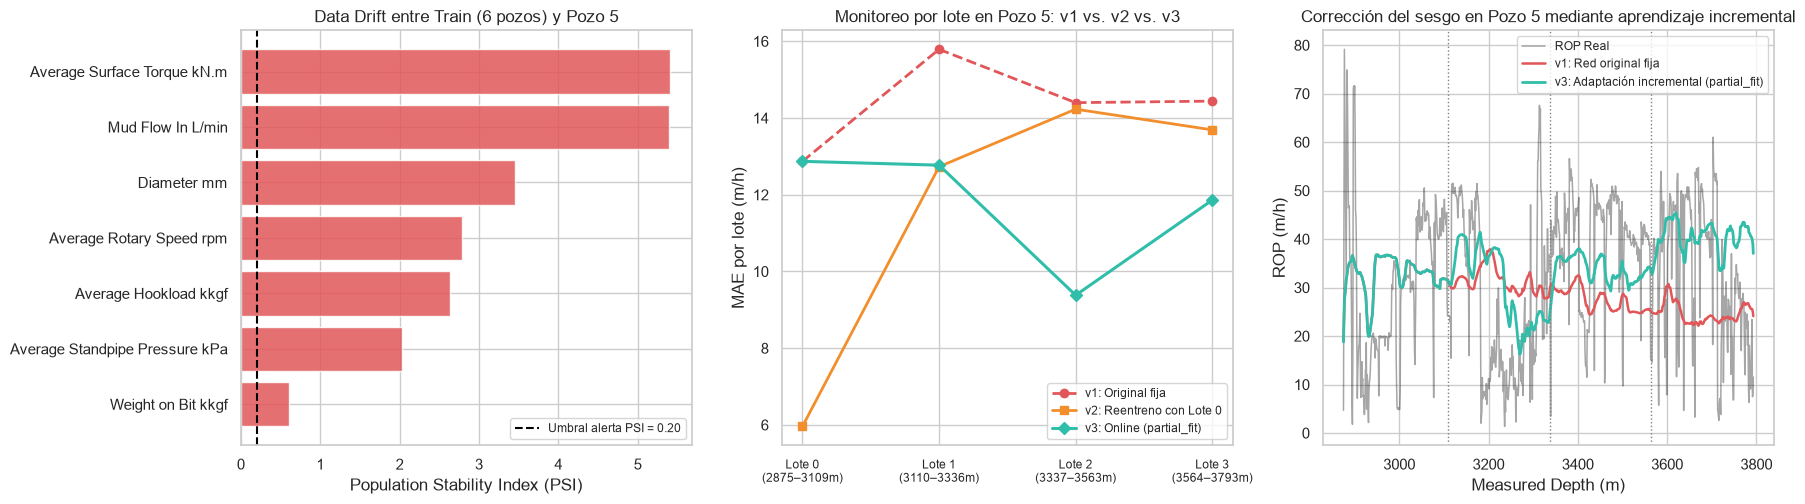

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
df_psi_plot = df_drift_global.sort_values('PSI', ascending=True)
axes[0].barh(df_psi_plot['Variable operativa'], df_psi_plot['PSI'], color='#e15759', alpha=0.85)
axes[0].axvline(0.2, color='black', linestyle='--', linewidth=1.5, label='Umbral alerta PSI = 0.20')
axes[0].set_xlabel('Population Stability Index (PSI)')
axes[0].set_title('Data Drift entre Train (6 pozos) y Pozo 5')
axes[0].legend(fontsize=8.5)

x_lotes = np.arange(N_LOTES)
axes[1].plot(x_lotes, df_monitoreo['MAE v1 (Original)'], 'o--', color='#e15759', linewidth=2, label='v1: Original fija')
axes[1].plot(x_lotes, df_monitoreo['MAE v2 (Reentreno L0)'], 's-', color='#f28e2b', linewidth=2, label='v2: Reentreno con Lote 0')
axes[1].plot(x_lotes, df_monitoreo['MAE v3 (Online partial_fit)'], 'D-', color='#30BEAA', linewidth=2.2, label='v3: Online (partial_fit)')
axes[1].set_xticks(x_lotes)
axes[1].set_xticklabels([f"Lote {i}\n({df_monitoreo['Tramo MD (m)'].iloc[i]}m)" for i in range(N_LOTES)], fontsize=8.5)
axes[1].set_ylabel('MAE por lote (m/h)')
axes[1].set_title('Monitoreo por lote en Pozo 5: v1 vs. v2 vs. v3')
axes[1].legend(fontsize=8.5)

axes[2].plot(md_p5, y_p5, color='black', alpha=0.35, linewidth=1.1, label='ROP Real')
axes[2].plot(md_p5, pd.Series(preds_v1_concat).rolling(15, min_periods=1).mean(), color='#e15759', linewidth=1.8, label='v1: Red original fija')
axes[2].plot(md_p5, pd.Series(preds_v3_concat).rolling(15, min_periods=1).mean(), color='#30BEAA', linewidth=2.0, label='v3: Adaptación incremental (partial_fit)')
for lote in lotes_df[1:]:
    axes[2].axvline(lote['Measured Depth m'].min(), color='gray', linestyle=':', linewidth=1)
axes[2].set_xlabel('Measured Depth (m)')
axes[2].set_ylabel('ROP (m/h)')
axes[2].set_title('Corrección del sesgo en Pozo 5 mediante aprendizaje incremental')
axes[2].legend(fontsize=8.5)
plt.tight_layout()
plt.show()

---

## Conclusiones integradoras

### 1. El escalado dentro de un `Pipeline` es obligatorio para entrenar redes neuronales sobre datos de perforación
Sin estandarizar las variables de entrada, la diferencia de órdenes de magnitud entre `Average Standpipe Pressure kPa` ($\sim 10^4$) y `Weight on Bit kkgf` ($\sim 10^1$) impide que el descenso por gradiente converja adecuadamente ($\text{RMSE Train} = 11,64\text{ m/h}$). Al integrar `StandardScaler` en el `Pipeline`, el error de entrenamiento se reduce a casi la mitad ($6,37\text{ m/h}$) sin filtrar estadísticas de los pozos de validación.

### 2. Las activaciones acotadas (`tanh` y `logistic`) y la regularización previenen extrapolaciones extremas entre pozos
- Mientras que las redes profundas con activación no acotada **`relu`** y tres capas ocultas `(128, 64, 32)` ($11.393\text{ parámetros}$) memorizan los pozos de entrenamiento ($\text{RMSE Train} = 5,61\text{ m/h}$) y sufren una fuerte degradación al evaluar en pozos nuevos ($\text{RMSE LOWO} = 23,27\text{ m/h}$, brecha de $17,66\text{ m/h}$), el uso combinado de **activación `tanh`**, **penalización $L_2$ (`alpha = 5.0`)** y **`early_stopping=True`** reduce el error en validación cruzada por pozo a **$\text{RMSE LOWO} = 17.63\text{ m/h}$** y **$\text{MAE LOWO} = 14.18\text{ m/h}$**, y en el **Pozo 5 (Holdout)** a **$\text{RMSE} = 16.46\text{ m/h}$** y **$\text{MAE} = 14.38\text{ m/h}$**.

### 3. El monitoreo con `Kolmogorov-Smirnov` y `PSI` detecta de forma temprana el cambio de régimen operativo (*Data Drift*)
Tanto el test **K-S** ($p < 10^{-50}$) como el **Population Stability Index (`PSI` $> 0,20$ en las 7 variables)** alertan automáticamente que el **Pozo 5** (perforado íntegramente en la sección profunda de $8,5\text{''}$ con alto torque medio de $20,54\text{ kN}\cdot\text{m}$ y menor caudal de $2.150,7\text{ L/min}$) tiene una distribución de entrada desplazada respecto del promedio global de los 6 pozos de entrenamiento. Además, lote a lote se observa que en los tramos finales del Pozo 5 (`Lote 2` y `Lote 3`, de $3.030\text{ a }3.483\text{ m}$) el peso sobre la mecha sube mientras el ROP real cae de $37,4\text{ m/h}$ a $25,8\text{ m/h}$ (**Concept Drift** litológico).

### 4. El aprendizaje incremental (`partial_fit`) permite adaptar la red neuronal durante la perforación del pozo
Al evaluar los lotes prospectivos del Pozo 5 (`Lotes 1 a 3`):
- La red estática original (**`v1`**) registra un **$\text{MAE} = 14.88\text{ m/h}$** ($\text{RMSE} = 16.84\text{ m/h}$).
- El reentrenamiento completo incorporando solo el tramo inicial (**`v2`**) mejora el desempeño a **$\text{MAE} = 13.55\text{ m/h}$** ($\text{RMSE} = 16.05\text{ m/h}$).
- La actualización incremental lote a lote mediante **`partial_fit` (`v3`)** alcanza el menor error en producción con **$\text{MAE} = 11.33\text{ m/h}$** ($\text{RMSE} = 13.72\text{ m/h}$), demostrando que la calibración continua de los pesos a medida que avanza el trépano es una solución efectiva para compensar la deriva litológica entre pozos.